# Confidence Intervals for the Rigor Appraisal

Turns the counts in the Scoring tab into interval estimates so the headline claims can be
stated with uncertainty attached rather than as bare proportions.

**Reads** `Data/Tracker/exports/scoring_long.csv`, filtered to the scope set below.
**Writes** four CSVs into the same `exports/` folder and one figure into `Drafts/figures/`.

**This notebook never touches `checklist_scoring_tracker.xlsx`.** It is read-only with respect
to the appraisal record. If any verdict changes, run `refresh_tracker.ipynb` first to rebuild
`scoring_long.csv`, then Run All here.

### Conventions

- A verdict counts as a success only if it is exactly `Yes`. `No` and `Unclear` both count as
  failures. `N/A` is excluded from the denominator (the `scoreable` flag in the source file).
- Intervals are two sided 95 percent confidence intervals.
- Only two contrasts are formally tested. Everything else is estimation, so no multiplicity
  correction is applied or needed.

### Scope

The headline analysis is the **primary set**, the eleven retinal and colonoscopy papers.
A twelve lead electrocardiogram is a time series rather than an image, so the four
electrocardiography papers form a prespecified **secondary set** that is reported
separately and never pooled into a headline figure. This follows reviewer feedback and is
logged as deviation D7.

Set `SCOPE` in the first code cell to `"SECONDARY"` or `"ALL"` to re-run everything on
another scope. Outputs for non primary scopes are written with a filename suffix so they
cannot overwrite the headline files.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm, beta, binom

ROOT    = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
EXPORTS = ROOT / "Data" / "Tracker" / "exports"
FIGDIR  = ROOT / "Drafts" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

SRC = EXPORTS / "scoring_long.csv"

# keep_default_na=False is required: the literal string "N/A" in the verdict column would
# otherwise be parsed as a missing value and silently change the denominators.
# SCOPE, set 2026-08-02 after reviewer feedback (deviation D7).
#   "PRIMARY"   the 11 retinal and colonoscopy papers. This is the headline analysis.
#   "SECONDARY" the 4 ECG papers, reported separately and never pooled with the primary set.
#   "ALL"       all 15, which reproduces the pre-revision figures.
# A 12-lead ECG is a time series and not an image, so ECG papers cannot sit in an appraisal
# titled "imaging". Change this one constant to re-run the whole notebook on another scope.
SCOPE = "PRIMARY"

long = pd.read_csv(SRC, keep_default_na=False)
assert "set" in long.columns, "scoring_long.csv predates the scope split; re-run refresh_tracker.ipynb"
_all_n = long["paper_id"].nunique()
if SCOPE != "ALL":
    long = long[long["set"] == SCOPE].copy()
SUFFIX = "" if SCOPE == "PRIMARY" else f"_{SCOPE.lower()}"
long["is_yes"]    = (long["verdict"] == "Yes").astype(int)
long["scoreable"] = (long["verdict"] != "N/A").astype(int)

ITEMS = (long[["item_no", "item"]].drop_duplicates()
         .sort_values("item_no").set_index("item_no")["item"].to_dict())

PAPERS = sorted(long["paper_id"].unique())
DOMAIN = long.drop_duplicates("paper_id").set_index("paper_id")["domain"].to_dict()

# wide views, indexed by paper, one column per item
verdict_w  = long.pivot(index="paper_id", columns="item_no", values="verdict")
yes_w      = long.pivot(index="paper_id", columns="item_no", values="is_yes")
scoreable_w= long.pivot(index="paper_id", columns="item_no", values="scoreable")

EXPECTED = {"PRIMARY": 11, "SECONDARY": 4, "ALL": 15}[SCOPE]
assert len(PAPERS) == EXPECTED, (SCOPE, len(PAPERS))
assert long.shape[0] == EXPECTED * 13, long.shape
assert len(ITEMS) == 13
assert set(long["verdict"]) <= {"Yes", "No", "Unclear", "N/A"}, set(long["verdict"])

print(f"source        {SRC.relative_to(ROOT)}")
print(f"SCOPE         {SCOPE}   ({len(PAPERS)} of {_all_n} papers)")
if SCOPE == "PRIMARY":
    print("              imaging only. The 4 ECG papers are the SECONDARY set and are")
    print("              reported separately, never pooled into these figures.")
print(f"papers        {len(PAPERS)}   items {len(ITEMS)}   cells {long.shape[0]}")
print(f"scoreable     {int(long.scoreable.sum())}   N/A {int((1 - long.scoreable).sum())}")
print(f"Yes           {int(long.is_yes.sum())}")
print()
print(long["verdict"].value_counts().to_string())

source        Data\Tracker\exports\scoring_long.csv
SCOPE         PRIMARY   (11 of 15 papers)
              imaging only. The 4 ECG papers are the SECONDARY set and are
              reported separately, never pooled into these figures.
papers        11   items 13   cells 143
scoreable     132   N/A 11
Yes           81

verdict
Yes        81
No         38
Unclear    13
N/A        11


## Interval methods

Several of the thirteen items sit at or near a boundary. The usual
normal approximation interval is useless there, so none is used.

| Purpose | Method | Why |
| --- | --- | --- |
| A single proportion | **Wilson score** | Best mean coverage at small n and never runs outside 0 to 1. Reported as the primary interval. |
| A single proportion | **Clopper-Pearson** | Exact and guaranteed conservative. Carried alongside so boundary cells can be read either way. |
| Difference between two items on the same papers | **Newcombe method 10** | The two proportions are measured on the same papers, so they are paired. Independent-sample methods would be wrong. |
| Same difference, tested | **Exact McNemar** | Uses only the discordant pairs, exact at small counts. |
| A rate pooled over several items | **Cluster bootstrap by paper** | Pooled group rates count several cells from each paper, so the cells are not independent. Resampling papers rather than cells keeps the clustering intact. |

In [2]:
CONF  = 0.95
ALPHA = 1 - CONF
Z     = norm.ppf(1 - ALPHA / 2)


def wilson(k, n, z=Z):
    """Wilson score interval for a binomial proportion."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom  = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half   = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, centre - half), min(1.0, centre + half))


def clopper_pearson(k, n, alpha=ALPHA):
    """Exact (conservative) interval from the beta quantiles."""
    if n == 0:
        return (np.nan, np.nan)
    lo = 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
    hi = 1.0 if k == n else beta.ppf(1 - alpha / 2, k + 1, n - k)
    return (float(lo), float(hi))


def paired_table(item_a, item_b):
    """2x2 counts over papers where BOTH items are scoreable.

    Returns (a, b, c, d, n) with
        a = Yes on both, b = Yes on A only, c = Yes on B only, d = Yes on neither.
    """
    keep = (scoreable_w[item_a] == 1) & (scoreable_w[item_b] == 1)
    ya, yb = yes_w.loc[keep, item_a].astype(bool), yes_w.loc[keep, item_b].astype(bool)
    a = int(( ya &  yb).sum())
    b = int(( ya & ~yb).sum())
    c = int((~ya &  yb).sum())
    d = int((~ya & ~yb).sum())
    return a, b, c, d, a + b + c + d


def mcnemar_exact(b, c):
    """Two sided exact McNemar p value from the discordant pairs."""
    n = b + c
    if n == 0:
        return 1.0
    return float(min(1.0, 2 * binom.cdf(min(b, c), n, 0.5)))


def newcombe_paired_diff(a, b, c, d):
    """Newcombe (1998) method 10 for the difference between paired proportions.

    delta = p_A - p_B where p_A = (a+b)/n and p_B = (a+c)/n.
    Square-and-add of the two Wilson intervals, with a correlation correction.
    """
    n  = a + b + c + d
    p1 = (a + b) / n
    p2 = (a + c) / n
    l1, u1 = wilson(a + b, n)
    l2, u2 = wilson(a + c, n)

    A   = (a + b) * (c + d) * (a + c) * (b + d)
    num = a * d - b * c
    if A == 0:
        phi = 0.0
    else:
        if num > 0:
            num = max(num - n / 2, 0.0)
        phi = num / np.sqrt(A)

    lo = (p1 - p2) - np.sqrt(max((p1 - l1)**2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2)**2, 0))
    hi = (p1 - p2) + np.sqrt(max((u1 - p1)**2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2)**2, 0))
    return (max(-1.0, lo), min(1.0, hi))


# --- one shared resample matrix so every bootstrap quantity below is mutually consistent ---
B_REPS = 20_000
rng    = np.random.default_rng(20260728)
BOOT_IDX = rng.integers(0, len(PAPERS), size=(B_REPS, len(PAPERS)))


def cluster_boot_rate(yes_per_paper, tot_per_paper, idx=BOOT_IDX):
    """Bootstrap distribution of a pooled rate, resampling PAPERS with replacement."""
    yes = np.asarray(yes_per_paper, float)
    tot = np.asarray(tot_per_paper, float)
    num = yes[idx].sum(axis=1)
    den = tot[idx].sum(axis=1)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, num / den, np.nan)


def pct_ci(draws, conf=CONF):
    lo, hi = np.nanpercentile(draws, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(lo), float(hi)


# --- structural checks on the interval code, so a silent formula error cannot pass ---
assert wilson(0, 15)[0] == 0.0 and wilson(15, 15)[1] == 1.0
assert clopper_pearson(0, 15)[0] == 0.0 and clopper_pearson(14, 14)[1] == 1.0
for k in (0, 3, 7, 14, 15):                       # Wilson must contain the point estimate
    lo, hi = wilson(k, 15)
    assert lo <= k / 15 <= hi, (k, lo, hi)
_t = (2, 9, 3, 6)                                  # Newcombe: reversing A and B must negate
_f = newcombe_paired_diff(*_t)
_r = newcombe_paired_diff(_t[0], _t[2], _t[1], _t[3])
assert np.allclose(_f, (-_r[1], -_r[0])), (_f, _r)
assert abs(mcnemar_exact(13, 0) - 2 * 0.5**13) < 1e-12

print("interval methods loaded and checked")
print(f"bootstrap     {B_REPS:,} resamples of {len(PAPERS)} papers, seed 20260728")
print(f"scope         {SCOPE}")

interval methods loaded and checked
bootstrap     20,000 resamples of 11 papers, seed 20260728
scope         PRIMARY


## Item level intervals

One row per checklist item. The denominator is the number of papers for which the item was
scoreable, so it varies between 13 and 15.

In [3]:
rows = []
for i, name in ITEMS.items():
    sub = long[long.item_no == i]
    n   = int(sub.scoreable.sum())
    k   = int(sub.is_yes.sum())
    wl, wh = wilson(k, n)
    cl, ch = clopper_pearson(k, n)
    rows.append({
        "item_no": i, "item": name,
        "yes": k, "scoreable": n, "n_na": len(sub) - n,
        "rate": k / n,
        "wilson_lo": wl, "wilson_hi": wh, "wilson_width": wh - wl,
        "cp_lo": cl, "cp_hi": ch,
    })

ci_item = pd.DataFrame(rows)
ci_item.to_csv(EXPORTS / f"ci_by_item{SUFFIX}.csv", index=False)

disp = ci_item.assign(
    rate_pct = lambda d: (d["rate"] * 100).round(1),
    wilson   = lambda d: [f"{lo*100:5.1f} to {hi*100:5.1f}" for lo, hi in zip(d.wilson_lo, d.wilson_hi)],
    cp       = lambda d: [f"{lo*100:5.1f} to {hi*100:5.1f}" for lo, hi in zip(d.cp_lo, d.cp_hi)],
)[["item_no", "item", "yes", "scoreable", "rate_pct", "wilson", "cp"]]
disp.columns = ["#", "item", "yes", "n", "rate %", "Wilson 95% CI", "Clopper-Pearson 95% CI"]

print("ITEM LEVEL, 95 PERCENT CONFIDENCE INTERVALS")
print("=" * 96)
print(disp.to_string(index=False))
print("=" * 96)
print(f"\nmean Wilson width  {ci_item.wilson_width.mean()*100:.1f} percentage points"
      f"   (denominators {ci_item.scoreable.min()} to {ci_item.scoreable.max()},"
      f" so no interval is narrow)")
print(f"wrote  {(EXPORTS / f'ci_by_item{SUFFIX}.csv').relative_to(ROOT)}")

ITEM LEVEL, 95 PERCENT CONFIDENCE INTERVALS
 #                      item  yes  n  rate %  Wilson 95% CI Clopper-Pearson 95% CI
 1       External Validation   10 11    90.9  62.3 to  98.4          58.7 to  99.8
 2         Patient-Level RCT    8 11    72.7  43.4 to  90.3          39.0 to  94.0
 3     Prespecified Endpoint    8 10    80.0  49.0 to  94.3          44.4 to  97.5
 4       Prespecified Design    7 10    70.0  39.7 to  89.2          34.8 to  93.3
 5      Registered w/ CT.gov    6 10    60.0  31.3 to  83.2          26.2 to  87.8
 6     Transparent Reporting    0 11     0.0   0.0 to  25.9           0.0 to  28.5
 7        Honest Impact Eval    7  9    77.8  45.3 to  93.7          40.0 to  97.2
 8   No Conflict of Interest    4 11    36.4  15.2 to  64.6          10.9 to  69.2
 9 Focus on Patient Outcomes    0 11     0.0   0.0 to  25.9           0.0 to  28.5
10      Adequate Sample Size    6 10    60.0  31.3 to  83.2          26.2 to  87.8
11        Intention-to-Treat    7  9    77.

## Group level rates, and which interval to quote

A pooled group rate such as clinical impact at 37 percent counts two cells from each of the
every paper. Treating those cells as independent observations understates the
uncertainty, because a paper that fails one clinical impact item tends to fail the other.

Neither available interval is unimprovable here, so both are computed and the choice between
them is made by a rule stated in advance rather than per number.

- The **naive Wilson** interval treats every cell as independent. For a group of several items
  that is false and the interval comes out too narrow.
- The **cluster bootstrap** resamples whole papers and so respects the clustering, but with
  so few clusters it is approximate, and at a boundary it degenerates. Transparency is
  zero in every paper in scope, so every resample also returns zero and the
  bootstrap reports an interval of zero width. That is an artifact, not a finding.

The rule applied below:

1. A group built from a **single item** has one cell per paper, so there is no clustering at
   all and Wilson is simply correct. Quote Wilson.
2. A group built from **several items** is clustered, so quote the cluster bootstrap.
3. If the bootstrap for such a group comes out **narrower** than the naive interval, that is
   the small cluster count showing through rather than a real gain in precision, so fall back
   to the wider naive interval.

The `quote_lo`, `quote_hi` and `quote_method` columns carry the result of that rule. Use them.

In [4]:
GROUPS = {
    "Model development":  [1, 13],
    "Trial conduct":      [3, 4, 5, 10, 11, 12],
    "Integrity":          [7, 8],
    "Clinical impact":    [2, 9],
    "Patient outcomes":   [9],
    "Transparency":       [6],
    "All items":          list(ITEMS),
}

group_draws = {}
rows = []
for gname, items in GROUPS.items():
    yes_pp = yes_w[items].sum(axis=1).reindex(PAPERS).to_numpy(float)
    tot_pp = scoreable_w[items].sum(axis=1).reindex(PAPERS).to_numpy(float)
    k, n   = int(yes_pp.sum()), int(tot_pp.sum())

    draws  = cluster_boot_rate(yes_pp, tot_pp)
    group_draws[gname] = draws
    blo, bhi = pct_ci(draws)
    nlo, nhi = wilson(k, n)

    # selection rule, stated in the markdown above and applied without exception
    if len(items) == 1:
        qlo, qhi, qm = nlo, nhi, "Wilson (one item per paper, unclustered)"
    elif (bhi - blo) < (nhi - nlo):
        qlo, qhi, qm = nlo, nhi, "Wilson (bootstrap narrower, 15 clusters)"
    else:
        qlo, qhi, qm = blo, bhi, "cluster bootstrap by paper"

    rows.append({
        "group": gname, "items": " ".join(map(str, items)), "n_items": len(items),
        "yes": k, "scoreable": n, "rate": k / n,
        "quote_lo": qlo, "quote_hi": qhi, "quote_method": qm,
        "boot_lo": blo, "boot_hi": bhi, "boot_se": float(np.nanstd(draws, ddof=1)),
        "naive_wilson_lo": nlo, "naive_wilson_hi": nhi,
    })

ci_group = pd.DataFrame(rows)
ci_group.to_csv(EXPORTS / f"ci_by_group{SUFFIX}.csv", index=False)

print("GROUP LEVEL RATES, 95 PERCENT CONFIDENCE INTERVALS")
print("=" * 108)
print(f"{'group':<19}{'items':<15}{'rate':>7}   {'QUOTE THIS':<18}{'method':<42}")
print("-" * 108)
for r in rows:
    print(f"{r['group']:<19}{r['items']:<15}{r['rate']*100:6.1f}%   "
          f"{r['quote_lo']*100:5.1f} to {r['quote_hi']*100:5.1f}   {r['quote_method']:<42}")
print("-" * 108)
print(f"{'':<19}{'':<15}{'':>7}   {'bootstrap':<18}{'naive Wilson':<18}")
for r in rows:
    print(f"{r['group']:<19}{'':<15}{'':>7}   "
          f"{r['boot_lo']*100:5.1f} to {r['boot_hi']*100:5.1f}   "
          f"{r['naive_wilson_lo']*100:5.1f} to {r['naive_wilson_hi']*100:5.1f}")
print("=" * 108)
print("\nTransparency shows the boundary artifact plainly. Zero papers in scope, so every")
print("bootstrap resample also returns zero and the bootstrap interval collapses to a point.")
print("Wilson gives 0.0 to 20.4, which is the honest statement.")
print(f"\nwrote  {(EXPORTS / f'ci_by_group{SUFFIX}.csv').relative_to(ROOT)}")

GROUP LEVEL RATES, 95 PERCENT CONFIDENCE INTERVALS
group              items             rate   QUOTE THIS        method                                    
------------------------------------------------------------------------------------------------------------
Model development  1 13             95.2%    77.3 to  99.2   Wilson (bootstrap narrower, 15 clusters)  
Trial conduct      3 4 5 10 11 12   72.4%    54.0 to  89.6   cluster bootstrap by paper                
Integrity          7 8              55.0%    31.6 to  77.3   cluster bootstrap by paper                
Clinical impact    2 9              36.4%    19.7 to  57.0   Wilson (bootstrap narrower, 15 clusters)  
Patient outcomes   9                 0.0%     0.0 to  25.9   Wilson (one item per paper, unclustered)  
Transparency       6                 0.0%     0.0 to  25.9   Wilson (one item per paper, unclustered)  
All items          1 2 3 4 5 6 7 8 9 10 11 12 13  61.4%    52.8 to  69.2   Wilson (bootstrap narrower, 15 clust

## The two prespecified contrasts

These are the only formal tests in the analysis. Both were stated in the proposal before the
appraisal began, so neither is a post hoc comparison and no multiplicity correction applies.

1. **Item 1 against item 9.** External validation against a genuine patient outcome. The
   sharpest single sentence version of the hypothesis.
2. **Model development against clinical impact.** The group level version of the same claim.

Both compare the same papers against themselves, so both are paired.

In [5]:
contrasts = []

# --- contrast 1, item against item, paired -----------------------------------------------
A_ITEM, B_ITEM = 1, 9
a, b, c, d, n = paired_table(A_ITEM, B_ITEM)
pA, pB = (a + b) / n, (a + c) / n
nlo, nhi = newcombe_paired_diff(a, b, c, d)
p_mc = mcnemar_exact(b, c)

# bootstrap the same difference as a cross check, using the shared resample matrix
yA = yes_w[A_ITEM].reindex(PAPERS).to_numpy(float)
yB = yes_w[B_ITEM].reindex(PAPERS).to_numpy(float)
one = np.ones(len(PAPERS))
d_draws = cluster_boot_rate(yA, one) - cluster_boot_rate(yB, one)
blo, bhi = pct_ci(d_draws)

print(f"CONTRAST 1   item 1 against item 9, paired over {n} papers")
print("=" * 78)
print(f"  {ITEMS[A_ITEM]:<28}{pA*100:6.1f}%   Wilson {wilson(a+b, n)[0]*100:5.1f} to {wilson(a+b, n)[1]*100:5.1f}")
print(f"  {ITEMS[B_ITEM]:<28}{pB*100:6.1f}%   Wilson {wilson(a+c, n)[0]*100:5.1f} to {wilson(a+c, n)[1]*100:5.1f}")
print()
print(f"  paired 2x2      both Yes {a}   item 1 only {b}   item 9 only {c}   neither {d}")
print(f"  difference      {(pA-pB)*100:.1f} percentage points")
print(f"  Newcombe 95%    {nlo*100:.1f} to {nhi*100:.1f}    <-- quote this")
print(f"  bootstrap 95%   {blo*100:.1f} to {bhi*100:.1f}    (shown for comparison only)")
print(f"  exact McNemar   p = {p_mc:.2e}   on {b + c} discordant papers")
print("=" * 78)
if c == 0 and (a + c) == 0:
    print(f"Item 9 is met by no paper in this scope, so every bootstrap resample also returns")
    print(f"zero and the interval runs to 100. That is the boundary failing, not precision.")
else:
    print(f"A resample of {n} papers can easily contain no copy of a paper that met item 9,")
    print(f"which is why the bootstrap runs to the boundary.")
print("The Newcombe interval is the one reported. Both agree the difference is large.")

contrasts.append({
    "scope": SCOPE,
    "contrast": "item 1 External Validation vs item 9 Focus on Patient Outcomes",
    "level": "item", "n_papers": n,
    "rate_a": pA, "rate_b": pB, "difference": pA - pB,
    "ci_lo": nlo, "ci_hi": nhi, "ci_method": "Newcombe method 10 (paired)",
    "boot_lo": blo, "boot_hi": bhi,
    "p_value": p_mc, "test": "exact McNemar",
    "discordant_b": b, "discordant_c": c,
})

CONTRAST 1   item 1 against item 9, paired over 11 papers
  External Validation           90.9%   Wilson  62.3 to  98.4
  Focus on Patient Outcomes      0.0%   Wilson   0.0 to  25.9

  paired 2x2      both Yes 0   item 1 only 10   item 9 only 0   neither 1
  difference      90.9 percentage points
  Newcombe 95%    52.3 to 98.4    <-- quote this
  bootstrap 95%   72.7 to 100.0    (shown for comparison only)
  exact McNemar   p = 1.95e-03   on 10 discordant papers
Item 9 is met by no paper in this scope, so every bootstrap resample also returns
zero and the interval runs to 100. That is the boundary failing, not precision.
The Newcombe interval is the one reported. Both agree the difference is large.


In [6]:
# --- contrast 2, group against group, clustered and paired --------------------------------
g1, g2 = "Model development", "Clinical impact"
r1 = ci_group.set_index("group").loc[g1, "rate"]
r2 = ci_group.set_index("group").loc[g2, "rate"]
gd = group_draws[g1] - group_draws[g2]            # shared resamples keep the pairing
glo, ghi = pct_ci(gd)

# paper level paired test on the same contrast: does each paper score higher on model
# development than on clinical impact? sign test over the papers with a non zero difference.
per_paper = pd.DataFrame({
    g1: yes_w[GROUPS[g1]].sum(1) / scoreable_w[GROUPS[g1]].sum(1),
    g2: yes_w[GROUPS[g2]].sum(1) / scoreable_w[GROUPS[g2]].sum(1),
}).reindex(PAPERS)
diff_pp = per_paper[g1] - per_paper[g2]
n_pos, n_neg = int((diff_pp > 0).sum()), int((diff_pp < 0).sum())
p_sign = mcnemar_exact(n_pos, n_neg)              # sign test is the same binomial computation

gi = ci_group.set_index("group")
print("CONTRAST 2   model development against clinical impact, clustered by paper")
print("=" * 78)
print(f"  {g1:<22}{r1*100:6.1f}%   {gi.loc[g1,'quote_lo']*100:5.1f} to {gi.loc[g1,'quote_hi']*100:5.1f}")
print(f"  {g2:<22}{r2*100:6.1f}%   {gi.loc[g2,'quote_lo']*100:5.1f} to {gi.loc[g2,'quote_hi']*100:5.1f}")
print()
print(f"  difference      {(r1-r2)*100:.1f} percentage points")
print(f"  bootstrap 95%   {glo*100:.1f} to {ghi*100:.1f}   (papers resampled, pairing kept)")
print(f"  paper level     {n_pos} of {len(PAPERS)} papers score higher on {g1.lower()}, "
      f"{n_neg} lower, {len(PAPERS) - n_pos - n_neg} tied")
print(f"  sign test       p = {p_sign:.2e}")
print("=" * 78)
print(f"{len(PAPERS)} clusters is few, so read the interval on the difference as approximate.")
print(f"The sign test needs no such caveat. {n_neg} papers of {len(PAPERS)} scored higher on")
print(f"clinical impact than on model development, and {n_pos} scored strictly lower.")

contrasts.append({
    "scope": SCOPE,
    "contrast": "group Model development vs group Clinical impact",
    "level": "group", "n_papers": len(PAPERS),
    "rate_a": r1, "rate_b": r2, "difference": r1 - r2,
    "ci_lo": glo, "ci_hi": ghi, "ci_method": "cluster bootstrap by paper",
    "boot_lo": glo, "boot_hi": ghi,
    "p_value": p_sign, "test": "sign test over papers",
    "discordant_b": n_pos, "discordant_c": n_neg,
})

ci_contrast = pd.DataFrame(contrasts)
ci_contrast.to_csv(EXPORTS / f"ci_contrasts{SUFFIX}.csv", index=False)
print(f"\nwrote  {(EXPORTS / f'ci_contrasts{SUFFIX}.csv').relative_to(ROOT)}")

CONTRAST 2   model development against clinical impact, clustered by paper
  Model development       95.2%    77.3 to  99.2
  Clinical impact         36.4%    19.7 to  57.0

  difference      58.9 percentage points
  bootstrap 95%   40.9 to 77.3   (papers resampled, pairing kept)
  paper level     10 of 11 papers score higher on model development, 0 lower, 1 tied
  sign test       p = 1.95e-03
11 clusters is few, so read the interval on the difference as approximate.
The sign test needs no such caveat. 0 papers of 11 scored higher on
clinical impact than on model development, and 10 scored strictly lower.

wrote  Data\Tracker\exports\ci_contrasts.csv


## Domain level intervals

Four retinal papers, seven colonoscopy, four electrocardiography. These intervals are computed
so that the width can be quoted, not so that the domains can be compared. At n of 4 a single
paper moves the rate by 25 points.

In [7]:
rows = []
for dom, dsub in long.groupby("domain"):
    for i, name in ITEMS.items():
        s = dsub[dsub.item_no == i]
        n = int(s.scoreable.sum())
        k = int(s.is_yes.sum())
        lo, hi = wilson(k, n)
        rows.append({"domain": dom, "item_no": i, "item": name,
                     "yes": k, "scoreable": n,
                     "rate": (k / n) if n else np.nan,
                     "wilson_lo": lo, "wilson_hi": hi,
                     "wilson_width": (hi - lo) if n else np.nan})

ci_domain = pd.DataFrame(rows).sort_values(["item_no", "domain"])
ci_domain.to_csv(EXPORTS / f"ci_by_domain{SUFFIX}.csv", index=False)

print("DOMAIN LEVEL, 95 PERCENT WILSON CONFIDENCE INTERVALS")
print("=" * 82)
DOMS_IN_SCOPE = [d for d in ["Retinal", "Colonoscopy", "ECG"] if d in set(long["domain"])]
DOM_N = {d: long[long.domain == d]["paper_id"].nunique() for d in DOMS_IN_SCOPE}
print(f"{'#':>2}  {'item':<28}" + "".join(f"{d + f' ({DOM_N[d]})':<17}" for d in DOMS_IN_SCOPE))
print("-" * 82)
for i, name in ITEMS.items():
    line = f"{i:>2}  {name:<28}"
    for dom in DOMS_IN_SCOPE:
        sel = ci_domain[(ci_domain.domain == dom) & (ci_domain.item_no == i)]
        if sel.empty:
            line += f"{'-':>15}  "
            continue
        r = sel.iloc[0]
        line += f"{r['rate']*100:3.0f}% [{r['wilson_lo']*100:3.0f},{r['wilson_hi']*100:3.0f}]   "
    print(line)
print("=" * 82)
print(f"\nmean interval width  {ci_domain.wilson_width.mean()*100:.0f} percentage points")
print(f"Across {len(ci_domain)} domain cells, every interval spans more than half the")
print("possible range. Domain rates are")
print("descriptive only and cannot support a claim that one domain differs from another.")
print(f"\nwrote  {(EXPORTS / f'ci_by_domain{SUFFIX}.csv').relative_to(ROOT)}")

DOMAIN LEVEL, 95 PERCENT WILSON CONFIDENCE INTERVALS
 #  item                        Retinal (4)      Colonoscopy (7)  
----------------------------------------------------------------------------------
 1  External Validation          75% [ 30, 95]   100% [ 65,100]   
 2  Patient-Level RCT            50% [ 15, 85]    86% [ 49, 97]   
 3  Prespecified Endpoint       100% [ 44,100]    71% [ 36, 92]   
 4  Prespecified Design         100% [ 44,100]    57% [ 25, 84]   
 5  Registered w/ CT.gov         67% [ 21, 94]    57% [ 25, 84]   
 6  Transparent Reporting         0% [  0, 49]     0% [  0, 35]   
 7  Honest Impact Eval           50% [  9, 91]    86% [ 49, 97]   
 8  No Conflict of Interest      25% [  5, 70]    43% [ 16, 75]   
 9  Focus on Patient Outcomes     0% [  0, 49]     0% [  0, 35]   
10  Adequate Sample Size        100% [ 44,100]    43% [ 16, 75]   
11  Intention-to-Treat          100% [ 44,100]    67% [ 30, 90]   
12  Balanced Table 1            100% [ 34,100]    86% [ 49, 

## Figure

A forest plot of the thirteen item rates with their Wilson intervals, ordered worst to best.
This is the single figure that carries the result.

wrote  Drafts\figures\item_rates_forest.png


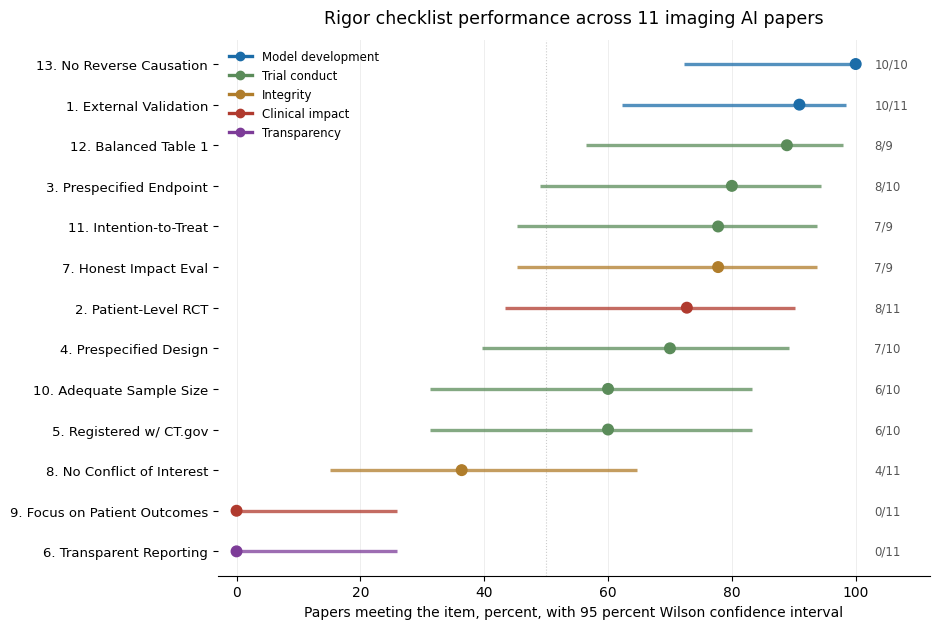

In [8]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ITEM_GROUP = {i: g for g, its in GROUPS.items() if g != "All items" for i in its
              if g not in ("Patient outcomes",)}
COLOUR = {"Model development": "#1b6ca8", "Trial conduct": "#5b8c5a",
          "Integrity": "#b07d2b", "Clinical impact": "#b03a2e", "Transparency": "#7d3c98"}

pl = ci_item.sort_values("rate", ascending=True).reset_index(drop=True)
pl["group"]  = pl["item_no"].map(ITEM_GROUP)
pl["colour"] = pl["group"].map(COLOUR)

fig, ax = plt.subplots(figsize=(9.5, 6.4))
y = np.arange(len(pl))
ax.hlines(y, pl.wilson_lo * 100, pl.wilson_hi * 100, color=pl.colour, lw=2.4, alpha=.75)
ax.scatter(pl.rate * 100, y, color=pl.colour, s=58, zorder=3)

for yi, r in pl.iterrows():
    # r["item"] not r.item -- attribute access would resolve to the Series .item() method
    ax.text(103, yi, f"{r['yes']}/{r['scoreable']}", va="center", fontsize=8.5, color="#555")

ax.set_yticks(y)
ax.set_yticklabels([f"{r['item_no']}. {r['item']}" for _, r in pl.iterrows()], fontsize=9.5)
ax.set_xlim(-3, 112)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Papers meeting the item, percent, with 95 percent Wilson confidence interval", fontsize=10)
ax.set_title(f"Rigor checklist performance across {len(PAPERS)} imaging AI papers"
             if SCOPE == "PRIMARY" else
             f"Rigor checklist performance, {SCOPE.lower()} set, {len(PAPERS)} papers",
             fontsize=12.5, pad=12)
ax.axvline(50, color="#ccc", lw=.8, ls=":", zorder=0)
ax.grid(axis="x", color="#eee", lw=.7, zorder=0)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.legend(handles=[Line2D([], [], color=c, lw=2.4, marker="o", ms=6, ls="-", label=g)
                   for g, c in COLOUR.items()],
          loc="upper left", frameon=False, fontsize=8.5)
fig.tight_layout()

OUT = FIGDIR / f"item_rates_forest{SUFFIX}.png"
fig.savefig(OUT, dpi=220, bbox_inches="tight")
print(f"wrote  {OUT.relative_to(ROOT)}")
plt.show()

## Two proportions recorded outside the checklist

The appraisal produced one empirical finding that the thirteen items do not record, so it has
no home in `scoring_long.csv`. The count below is entered by hand from the reading notes and is
flagged as such. It is not derived from the tracker and will not update if a verdict changes.

Because it is hand entered, it had to be re-derived when the scope narrowed rather than simply
rescoped. Doing so reconciled exactly with the figure reported under the previous scope. A second
hand entered statistic about enrolment targets did not survive that check and was dropped, which
is recorded in the code comment below. A statistic that cannot be re-derived should not be
reported.

In [9]:
# HAND ENTERED from the appraisal notes, not derived from the tracker. Update here if the
# underlying reading changes. See Drafts/hypothesis_assessment.md, section on power.
# Re-derived 2026-08-02 for the primary set. The 12 randomised trials split 8 primary and
# 4 secondary, so the previously reported 7 of 12 had to be recomputed rather than reused.
# It reconciles: 6 primary + 1 secondary (Yao) = the original 7.
#
# An earlier companion statistic, "randomised trials that clearly met their enrolment target",
# was DROPPED rather than rescoped. It rested on Liu, which is now in the secondary set, and
# the reading notes do not record a stated enrolment target for Wolf or Repici, so the primary
# set figure could not be derived without guessing. Dropped in preference to inventing it.
HAND = [
    ("Randomised trials in the PRIMARY set whose power calculation assumed a baseline "
     "event rate the observed data contradicted. Kader (APC 0.83 planned vs 0.62), "
     "Ahmad (PDR 20% vs 79.7%), Wei (APC 1.070 vs 0.67), Repici (ADR 35% vs 40.4%), "
     "Alali (ADR 10% vs 42.2%), Hsu (ADR 48% vs 53.3%). Wolf and Mathenge are clean.", 6, 8),
]

print("HAND ENTERED PROPORTIONS, 95 PERCENT CONFIDENCE INTERVALS")
print("=" * 78)
for label, k, n in HAND:
    wl, wh = wilson(k, n)
    cl, ch = clopper_pearson(k, n)
    print(f"  {k} of {n} = {k/n*100:.1f}%")
    print(f"    Wilson          {wl*100:.1f} to {wh*100:.1f}")
    print(f"    Clopper-Pearson {cl*100:.1f} to {ch*100:.1f}")
    print(f"    {label}")
    print()
print("=" * 78)

HAND ENTERED PROPORTIONS, 95 PERCENT CONFIDENCE INTERVALS
  6 of 8 = 75.0%
    Wilson          40.9 to 92.9
    Clopper-Pearson 34.9 to 96.8
    Randomised trials in the PRIMARY set whose power calculation assumed a baseline event rate the observed data contradicted. Kader (APC 0.83 planned vs 0.62), Ahmad (PDR 20% vs 79.7%), Wei (APC 1.070 vs 0.67), Repici (ADR 35% vs 40.4%), Alali (ADR 10% vs 42.2%), Hsu (ADR 48% vs 53.3%). Wolf and Mathenge are clean.



## How to quote these numbers

- For any **single item rate**, quote the Wilson interval from `ci_by_item.csv`.
- For any **pooled group rate**, quote `quote_lo` and `quote_hi` from `ci_by_group.csv` and
  name the method in `quote_method`. Do not pick between the two candidate intervals by hand.
- For the **item 1 against item 9** contrast, quote the Newcombe interval and the exact
  McNemar p value.
- For the **group contrast**, lead with the sign test. The interval on the difference rests on
  few clusters and should be called approximate.
- Do not quote **domain rates** as estimates. Every domain interval is wider than fifty points.

What a sample this size can and cannot support is now visible. The direction is established beyond
reasonable doubt, because the comparison is paired and almost every paper falls the same way.
The magnitude is not. No item rate is pinned down to better than twenty percentage points and
the median interval width is thirty eight. A claim of the form "these papers validate far more
often than they measure outcomes" is supported. A claim of the form "exactly 93 percent do X" is not.

Two of the intervals deserve to be quoted specifically because they look weak. Zero on transparency and zero on
patient outcomes both give intervals whose upper bound is well above zero, so neither result
excludes a true rate of roughly one paper in four. Reporting those honestly is stronger than
reporting a bare zero, because the conclusion survives even at the top of both intervals.

In [10]:
print("OUTPUTS")
print("=" * 70)
for f in [f"ci_by_item{SUFFIX}.csv", f"ci_by_group{SUFFIX}.csv",
          f"ci_contrasts{SUFFIX}.csv", f"ci_by_domain{SUFFIX}.csv"]:
    p = EXPORTS / f
    print(f"  {'OK ' if p.exists() else 'MISSING':<4}{p.relative_to(ROOT)}")
p = FIGDIR / f"item_rates_forest{SUFFIX}.png"
print(f"  {'OK ' if p.exists() else 'MISSING':<4}{p.relative_to(ROOT)}")
print("=" * 70)
print(f"\nSCOPE = {SCOPE}   ({len(PAPERS)} papers)")
print("\nALL CELLS EXECUTED CLEANLY")
print("checklist_scoring_tracker.xlsx was not opened or modified by this notebook.")

OUTPUTS
  OK  Data\Tracker\exports\ci_by_item.csv
  OK  Data\Tracker\exports\ci_by_group.csv
  OK  Data\Tracker\exports\ci_contrasts.csv
  OK  Data\Tracker\exports\ci_by_domain.csv
  OK  Drafts\figures\item_rates_forest.png

SCOPE = PRIMARY   (11 papers)

ALL CELLS EXECUTED CLEANLY
checklist_scoring_tracker.xlsx was not opened or modified by this notebook.
